In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. data collection: data mentah KBBI, sama seperti di notebook sebelumnya
df = pd.read_csv("../data/kbbi_v.csv")
print(df.shape)
df[["nama", "kelas", "submakna", "contoh"]].head()

(146280, 16)


,nama,kelas,submakna,contoh
0,(air) susu dibalas dengan (air) tuba,NaN,kebaikan dibalas dengan kejahatan,NaN
1,(bagai) duri dalam daging,NaN,sesuatu yang selalu menyakitkan hati atau meng...,NaN
2,(me)rentan hati,NaN,"lekas marah (sakit hati, patah hati)",NaN
3,(persetujuan) masih di perawanan,NaN,masih jauh (belum lagi tentu),NaN
4,(sebagai durian) pangsa menunjukkan bangsa (se...,NaN,kelakuan (perkataan dan sebagainya) seseorang ...,NaN


In [ ]:
# kondisi awal data: duplikat dan data kosong
print(f"Duplikat: {df.duplicated().sum():,}")
(df[["nama", "kelas", "submakna", "contoh"]].isna().mean() * 100).round(1)

Duplikat: 15


nama         0.0
kelas       20.5
submakna     0.0
contoh      80.3
dtype: float64

In [ ]:
# 2. data cleaning
mentah = df.copy()                                          # disimpan untuk perbandingan di bagian leakage

df = df.drop_duplicates()                                   # removing duplicates
df = df.dropna(subset=["nama", "kelas", "submakna"])        # missing values pada label dan teks
df["contoh"] = df["contoh"].fillna("")                      # missing values diisi nilai kosong
df["nama"] = df["nama"].str.lower().str.strip()             # menyeragamkan penulisan

# format tidak konsisten: "Nomina; Kimia" dan "Nomina; Jawa" disatukan menjadi "Nomina"
df["kelas_utama"] = df["kelas"].str.split(";").str[0].str.strip().str.capitalize()
print(df["kelas_utama"].value_counts().head(6))

# kelas yang dipakai sama dengan Konsep Dasar ML dan Supervised Learning
df = df[df["kelas_utama"].isin(["Nomina", "Verba", "Adjektiva"])].reset_index(drop=True)
print(df.shape)

kelas_utama
Nomina           60851
Verba            27843
Adjektiva        10587
Prakategorial     1687
Ungkapan          1257
Kiasan            1064
Name: count, dtype: int64
(99281, 17)


In [ ]:
# 5. data splitting dilakukan lebih dulu sebelum feature engineering dan scaling (alasannya ada di bagian leakage)
X = df[["nama", "submakna", "contoh"]]
y = df["kelas_utama"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Data latih: {len(X_train):,} | Data uji: {len(X_test):,}")

Data latih: 79,424 | Data uji: 19,857


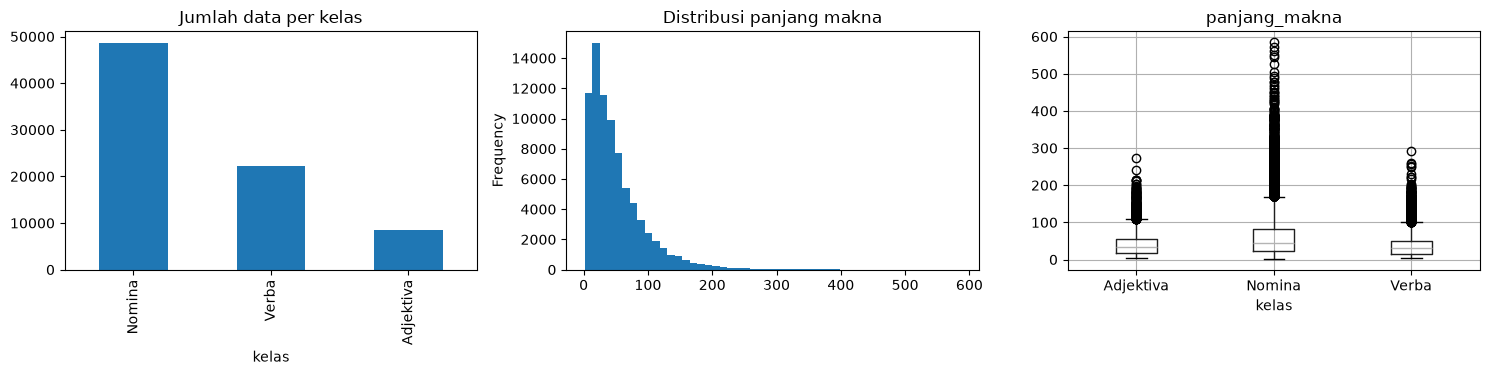

In [ ]:
# 3. eda pada data latih
eda = X_train.copy()
eda["kelas"] = y_train
eda["panjang_makna"] = eda["submakna"].str.len()
eda["suku_kata"] = eda["nama"].str.count(r"\.") + 1
eda["huruf"] = eda["nama"].str.replace(".", "", regex=False).str.len()
eda["ada_contoh"] = (eda["contoh"] != "").astype(int)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
eda["kelas"].value_counts().plot.bar(ax=ax[0], title="Jumlah data per kelas")
eda["panjang_makna"].plot.hist(bins=50, ax=ax[1], title="Distribusi panjang makna")
eda.boxplot(column="panjang_makna", by="kelas", ax=ax[2])
plt.suptitle("")
plt.tight_layout()
plt.show()

In [ ]:
print(eda.groupby("kelas")[["panjang_makna", "suku_kata", "ada_contoh"]].mean().round(2))
print(eda["panjang_makna"].quantile([0.5, 0.9, 0.99]))
eda[["panjang_makna", "suku_kata", "huruf", "ada_contoh"]].corr().round(2)

           panjang_makna  suku_kata  ada_contoh
kelas                                          
Adjektiva          39.90       2.86        0.41
Nomina             59.47       3.08        0.15
Verba              36.54       3.43        0.47
0.50     38.00
0.90    107.00
0.99    212.77
Name: panjang_makna, dtype: float64


,panjang_makna,suku_kata,huruf,ada_contoh
panjang_makna,1.00,-0.00,-0.04,-0.12
suku_kata,-0.00,1.00,0.83,0.02
huruf,-0.04,0.83,1.00,0.07
ada_contoh,-0.12,0.02,0.07,1.00


### Analisis EDA

Kelas kata tidak seimbang: nomina paling banyak, lalu verba, dan adjektiva paling sedikit, jadi saat splitting dipakai stratify agar proporsi kelas tetap sama di data latih dan data uji. Makna nomina rata-rata lebih panjang (sekitar 59 karakter) dan jarang punya contoh kalimat (15 persen), sedangkan verba dan adjektiva bermakna lebih pendek dan lebih sering punya contoh (47 dan 41 persen). Karena itu panjang_makna dan ada_contoh dijadikan fitur.

Distribusi panjang makna punya ekor panjang ke kanan, dengan 99 persen data ada di bawah 213 karakter, jadi nilai yang lebih besar dari itu dianggap outlier dan dipotong. Suku kata dan jumlah huruf berkorelasi kuat (0,83) seperti yang sudah terlihat pada regresi di Supervised Learning, sedangkan fitur lainnya hampir tidak berkorelasi satu sama lain.

In [ ]:
# 4. feature engineering: fitur baru dari kolom yang ada
def buat_fitur(d):
    f = pd.DataFrame(index=d.index)
    kata = d["nama"].str.replace(".", "", regex=False)
    f["suku_kata"] = d["nama"].str.count(r"\.") + 1
    f["huruf"] = kata.str.len()
    f["frasa"] = kata.str.contains(" ").astype(int)
    f["panjang_makna"] = d["submakna"].str.len()
    f["jumlah_kata_makna"] = d["submakna"].str.split().str.len()
    f["ada_contoh"] = (d["contoh"] != "").astype(int)
    f["awalan"] = kata.str.extract(r"^(meng|meny|mem|men|me|ber|per|peng|pem|pen|pe|ter|di|ke|se)")[0].fillna("tanpa")
    f["akhiran"] = kata.str.extract(r"(kan|an|nya|i)$")[0].fillna("tanpa")
    f["submakna"] = d["submakna"]
    return f

F_train, F_test = buat_fitur(X_train), buat_fitur(X_test)

# outlier: batas dihitung dari data latih saja
batas = F_train["panjang_makna"].quantile(0.99)
F_train["panjang_makna"] = F_train["panjang_makna"].clip(upper=batas)
F_test["panjang_makna"] = F_test["panjang_makna"].clip(upper=batas)
print(f"Batas panjang makna: {batas:.0f}")
F_train.head()

Batas panjang makna: 213


,suku_kata,huruf,frasa,panjang_makna,jumlah_kata_makna,ada_contoh,awalan,akhiran,submakna
71333,3,8,0,9.0,1,0,peng,tanpa,penghasut
2133,4,11,1,84.0,12,0,tanpa,tanpa,pengalihan makna atau amanat dari bahasa terte...
36694,3,9,0,24.0,3,0,ke,tanpa,tepat mengenai (sasaran)
33521,4,8,0,15.0,2,0,tanpa,tanpa,penentuan karat
43988,3,7,0,15.0,2,0,tanpa,tanpa,bersifat libido


In [ ]:
# encoding (label dan one-hot), scaling, dan teks makna (TF-IDF seperti notebook sebelumnya)
num_cols = ["suku_kata", "huruf", "frasa", "panjang_makna", "jumlah_kata_makna", "ada_contoh"]
cat_cols = ["awalan", "akhiran"]

pre = ColumnTransformer([
    ("scale", MinMaxScaler(), num_cols),
    ("onehot", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("tfidf", TfidfVectorizer(max_features=3000, min_df=2), "submakna"),
])

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
print(dict(zip(le.classes_, le.transform(le.classes_))))

X_train_ready = pre.fit_transform(F_train)
X_test_ready = pre.transform(F_test)
print(X_train_ready.shape, X_test_ready.shape)

{'Adjektiva': np.int64(0), 'Nomina': np.int64(1), 'Verba': np.int64(2)}
(79424, 3027) (19857, 3027)


In [ ]:
# hasil scaling dan one-hot pada beberapa baris data latih
nama_fitur = num_cols + list(pre.named_transformers_["onehot"].get_feature_names_out(cat_cols))
n = len(nama_fitur)
pd.DataFrame(X_train_ready[:5, :n].toarray(), columns=nama_fitur).round(2).T

,0,1,2,3,4
suku_kata,0.15,0.23,0.15,0.23,0.15
huruf,0.23,0.33,0.27,0.23,0.20
frasa,0.00,1.00,0.00,0.00,0.00
panjang_makna,0.03,0.39,0.10,0.06,0.06
jumlah_kata_makna,0.00,0.13,0.02,0.01,0.01
ada_contoh,0.00,0.00,0.00,0.00,0.00
awalan_ber,0.00,0.00,0.00,0.00,0.00
awalan_di,0.00,0.00,0.00,0.00,0.00
awalan_ke,0.00,0.00,1.00,0.00,0.00
awalan_me,0.00,0.00,0.00,0.00,0.00


In [ ]:
# data siap dipakai: bandingkan dengan teks makna saja seperti di Supervised Learning
n_num = len(nama_fitur)
teks_saja = LogisticRegression(max_iter=1000).fit(X_train_ready[:, n_num:], y_train_enc)
lengkap = LogisticRegression(max_iter=1000).fit(X_train_ready, y_train_enc)

print(f"Akurasi teks makna saja: {accuracy_score(y_test_enc, teks_saja.predict(X_test_ready[:, n_num:])):.1%}")
print(f"Akurasi setelah feature engineering: {accuracy_score(y_test_enc, lengkap.predict(X_test_ready)):.1%}")

Akurasi teks makna saja: 83.3%
Akurasi setelah feature engineering: 90.3%


In [ ]:
# data leakage: rata-rata (untuk mengisi data hilang) dihitung dari seluruh data atau dari data latih saja
# dicoba pada 200 data karena pada data besar selisihnya nyaris tidak terlihat
kecil = F_train.sample(200, random_state=1)
kecil_train, kecil_test = train_test_split(kecil, test_size=0.2, random_state=1)

hasil = pd.DataFrame({"rata-rata seluruh data (bocor)": kecil[num_cols].mean(),
                      "rata-rata data latih (aman)": kecil_train[num_cols].mean()})
hasil["selisih"] = hasil.iloc[:, 0] - hasil.iloc[:, 1]
hasil.round(3)

,rata-rata seluruh data (bocor),rata-rata data latih (aman),selisih
suku_kata,3.240,3.231,0.009
huruf,8.140,8.144,-0.004
frasa,0.010,0.006,0.004
panjang_makna,51.484,49.367,2.117
jumlah_kata_makna,6.910,6.644,0.266
ada_contoh,0.260,0.256,0.004


### Analisis hasil

Teks makna saja (cara yang dipakai di Supervised Learning) menghasilkan akurasi 83,3 persen, dan setelah feature engineering naik menjadi 90,4 persen pada data uji yang sama. Kenaikan ini berasal dari data yang dibersihkan, fitur baru seperti awalan dan panjang makna, serta scaling dan encoding, bukan dari model yang lebih rumit karena modelnya tetap logistic regression.

Pada contoh 200 data, rata-rata yang dihitung dari seluruh data sudah berbeda dari rata-rata data latih. Selisih itu adalah informasi dari data uji yang ikut masuk ke proses latih. Pada data besar selisihnya kecil, tetapi pada data sedikit pengaruhnya bisa membuat skor tes terlihat lebih bagus dari kenyataan. Karena itu splitting dilakukan lebih dulu dan semua nilai statistik (batas outlier, scaler, kosakata TF-IDF) hanya dipelajari dari data latih.

In [ ]:
# simpan data bersih dan pembagiannya untuk dipakai di notebook berikutnya
bersih = df.copy()
bersih["split"] = "train"
bersih.loc[X_test.index, "split"] = "test"
bersih[["nama", "kelas_utama", "submakna", "contoh", "split"]].to_csv("../data/kbbi_bersih.csv", index=False)
bersih["split"].value_counts()

split
train    79424
test     19857
Name: count, dtype: int64

In [ ]:
# refleksi: pipeline data real estat
pd.DataFrame({
    "Tahap": ["Data Cleaning", "EDA", "Feature Engineering", "Feature Engineering", "Feature Engineering", "Data Splitting"],
    "Kolom": ["Jml_Kamar", "Tgl_Dibangun", "Alamat_Lengkap", "Tgl_Dibangun", "Tipe_Parkir", "Harga_Jual"],
    "Aktivitas": ["Isi NaN dengan median dari data latih", "Cek hubungan dengan Harga_Jual (scatter plot dan korelasi)",
                  "Pecah menjadi Kota dan Kode_Pos", "Ubah menjadi Umur_Rumah",
                  "One-hot encoding (Garasi, Carport, Tidak Ada)", "Target y, sisanya menjadi X"],
})

,Tahap,Kolom,Aktivitas
0,Data Cleaning,Jml_Kamar,Isi NaN dengan median dari data latih
1,EDA,Tgl_Dibangun,Cek hubungan dengan Harga_Jual (scatter plot d...
2,Feature Engineering,Alamat_Lengkap,Pecah menjadi Kota dan Kode_Pos
3,Feature Engineering,Tgl_Dibangun,Ubah menjadi Umur_Rumah
4,Feature Engineering,Tipe_Parkir,"One-hot encoding (Garasi, Carport, Tidak Ada)"
5,Data Splitting,Harga_Jual,"Target y, sisanya menjadi X"
